In [1]:
source('../../../R/preamble.R')

# Growth dynamics
(gamma only)

In [2]:
d = read.tsv('../../../datasets/growth_curves/2025-04-15_DE_alpha/growth_dynamics_esch_DE_alpha.tsv')

In [3]:
library(stats)

# Simple spline-based GCV smoothing function
smooth_spline <- function(x, y, df) {

  # Sort by time to ensure proper interpolation
  ord <- order(x)
  x <- x[ord]
  y <- y[ord]
  
  # Perform spline interpolation
  fit <- smooth.spline(
    x = x,
    y = y,
    df = df
  )

  return(predict(fit, x = x)$y)
}

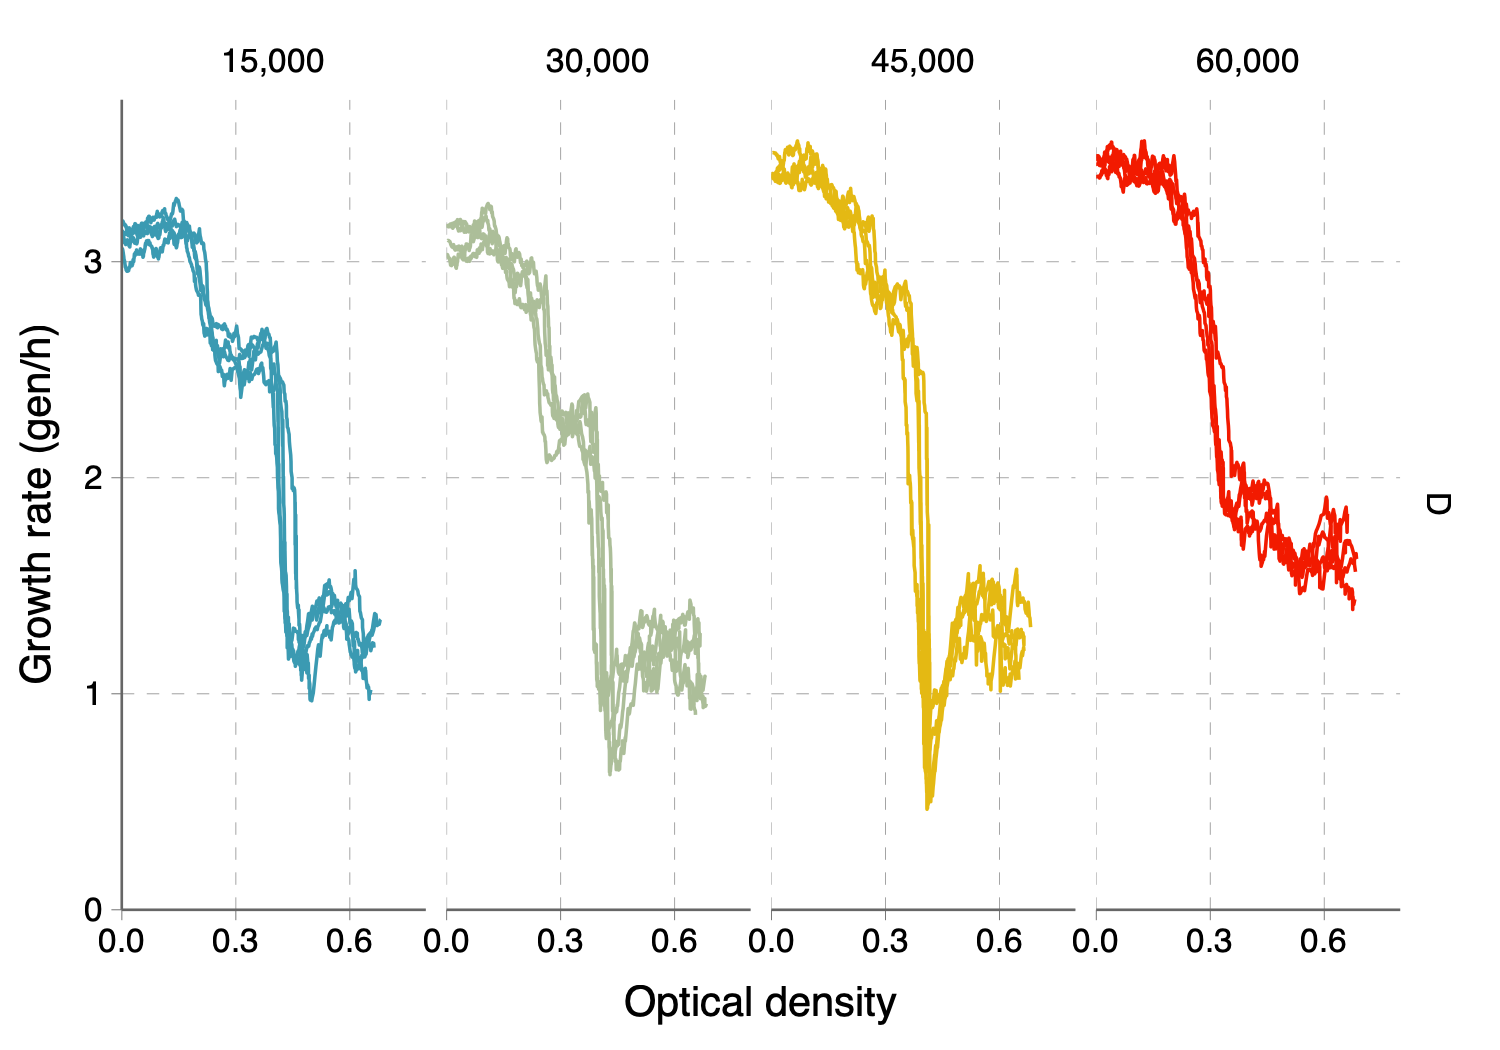

In [4]:
lwd = 0.4
lwd_wt = 0.2

wt_color = 'grey50'

max_od = 0.8

size(3.5, 5)

df = 50 # degrees of freedom for smoothing

d_smooth =
d %>%
    arrange(well, o_filt) %>% 

    group_by(well, rep) %>%
    mutate(
        gr_filt = 60/tau_filt,
        gr_smooth = smooth_spline(o_filt, gr_filt, df)
        ) %>%
    ungroup()

d_trim = d_smooth %>% filter(o_filt <= max_od, strain == 'D')

d_trim %>%
    filter(strain != 'WT') %>% 
    mutate(genk = paste0(gen * 2.5, ',000')) %>% 

ggplot() + aes(o_filt, gr_filt, col = gen, group = paste(well, rep)) +
    nl +
    facet_grid(strain ~ genk) +
    xcont(NA, max_od, breaks = seq(0, 0.6, 0.3)) + 
    ycont(0, 3.75, breaks = seq(0, 3, 1)) +

    geom_line(data = d_trim %>% filter(strain == 'WT') %>% select(-strain, -gen), col = wt_color, lwd = lwd_wt) +
    geom_line(lwd = lwd) +

    #annotate(geom = 'text', x = 0.1, y = 3.05, label = 'WT', size = 3.5, fontface = 'bold', col = b) +
    #annotate(geom = 'text', x = 0.27, y = 3.6, label = '60k', size = 3.5, fontface = 'bold', col = pal[2]) +

    labs(x = 'Optical density', y = 'Growth rate (gen/h)')

psave('Plots/growth_rate_vs_od')

# Pooled version

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by strain, gen, and o_smooth.
ℹ Output is grouped by strain and gen.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(strain, gen, o_smooth))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


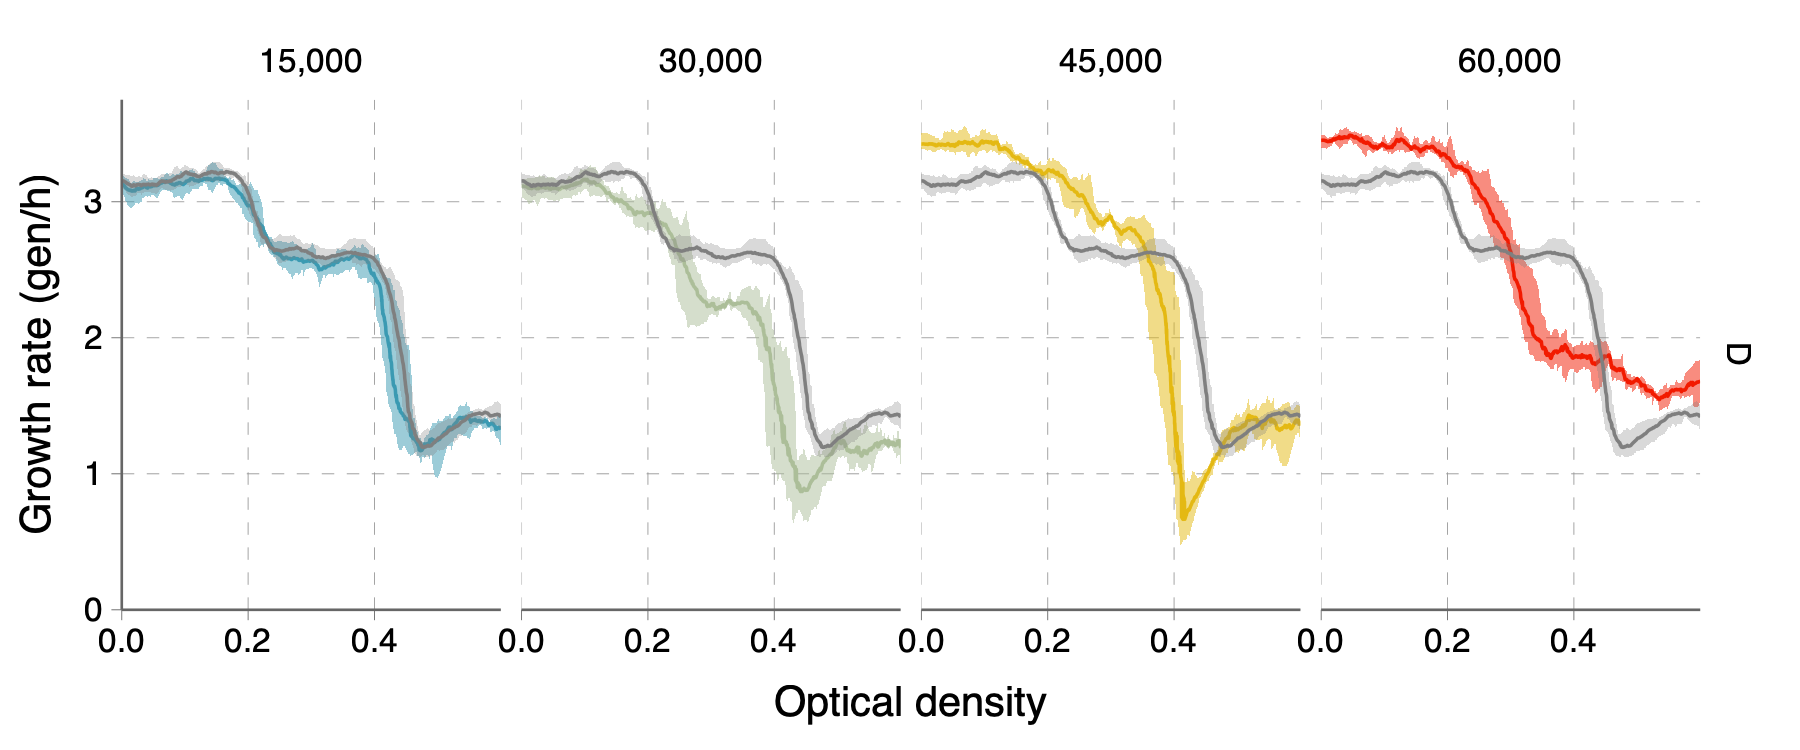

In [5]:
max_od = 0.6
resolution = 1e-4

d_interp =
d %>% 
    mutate(gr_filt = 60/tau_filt) %>% 

    group_by(well, name, strain, gen, rep) %>%
    group_modify(~{
        o_smooth <- seq(0, max_od, by = resolution)
        interp_values <- approx(
          x = .x$o_filt,
          y = .x$gr_filt,
          xout = o_smooth,
          method = "linear",
          rule = 2  # extrapolate if needed
        )
        data.frame(
          o_smooth = interp_values$x,
          gr_smooth = interp_values$y
        )
      }) %>%
    ungroup() 

d_sum =
d_interp %>% 
    group_by(strain, gen, o_smooth) %>%
    summarise(
        m = mean(gr_smooth),
        s = sd(gr_smooth),
        mn = min(gr_smooth), mx = max(gr_smooth)
        ) %>%
    ungroup()

ribbon_alpha = 0.5
ribbon_alpha_wt = 0.3

lwd = 0.4
lwd_wt = 0.4

size(2.5, 6)

d_sum %>% 
    filter(strain != 'WT', strain != 'E') %>% 
    mutate(genk = paste0(gen * 2.5, ',000')) %>% 

ggplot() + aes(o_smooth, 
               m, ymin = mn, ymax = mx,
               #ymin = m - s, ymax = m + s,
               col = gen,
               ) +
    nl +
    facet_grid(strain ~ genk) +

    xcont(0, max_od, breaks = seq(0, 0.5, 0.2)) + ycont(0, 3.75, breaks = seq(0, 3, 1)) +

    geom_ribbon(col = NA, alpha = ribbon_alpha, aes(fill = gen)) +
    geom_line(lwd = lwd) +

    geom_ribbon(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = NA, fill = wt_color, alpha = ribbon_alpha_wt) +
    geom_line(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = wt_color, lwd = lwd_wt) +

    #annotate(geom = 'text', x = 0.19, y = 2.7, label = 'WT', size = 3, fontface = 'bold', col = wt_color) +
    #annotate(geom = 'text', x = 0.35, y = 3.1, label = '60k', size = 3, fontface = 'bold', col = pal[2]) +

    labs(x = 'Optical density', y = 'Growth rate (gen/h)')

psave('Plots/growth_rate_vs_od_pooled')

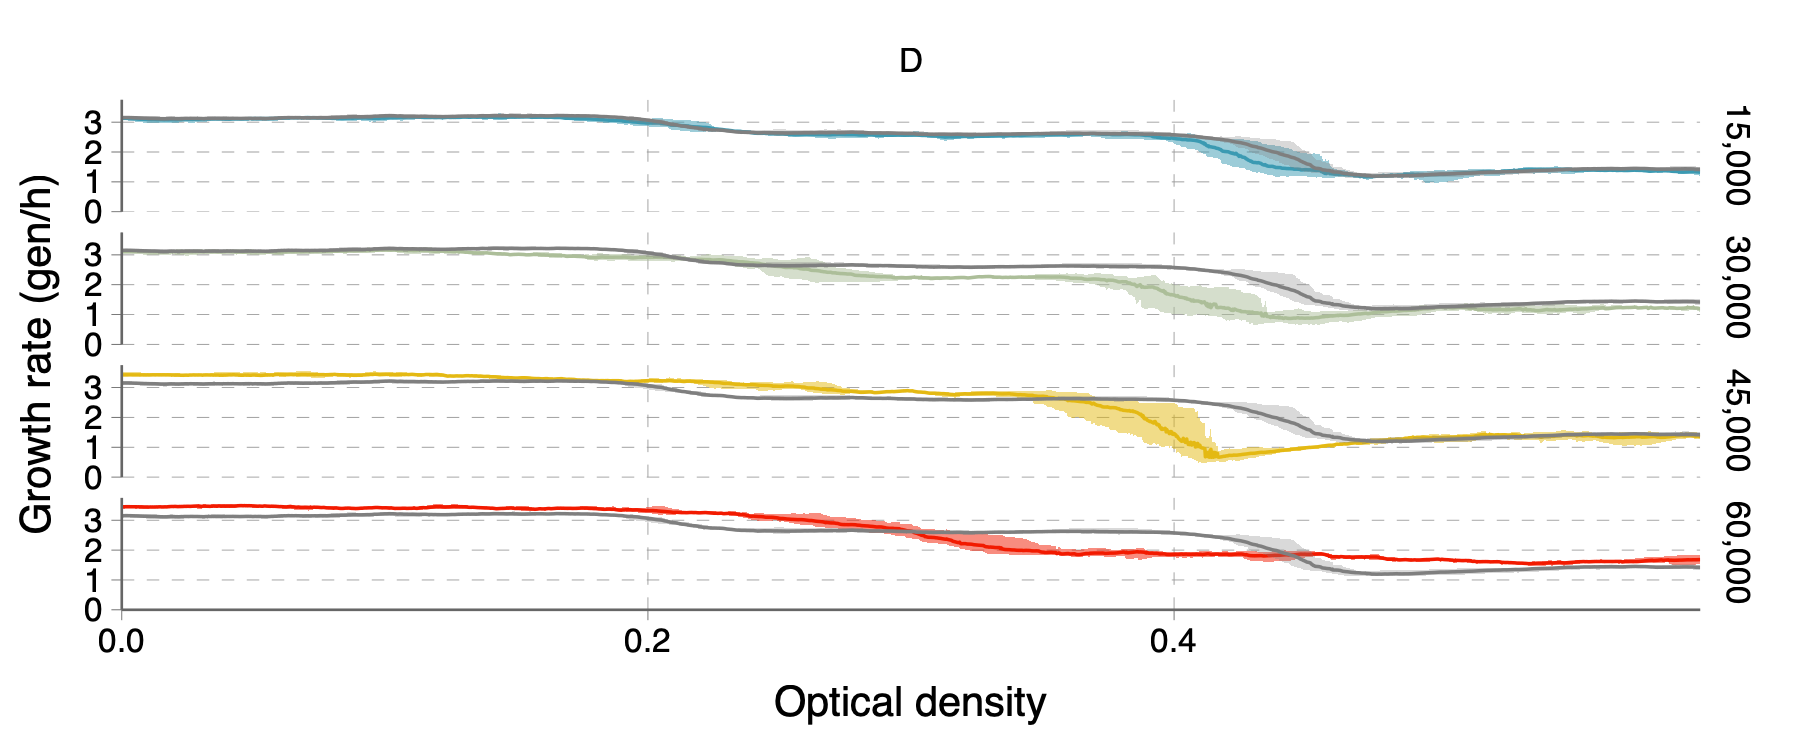

In [6]:
d_sum %>% 
    filter(strain != 'WT', strain == 'D') %>% 
    mutate(genk = paste0(gen * 2.5, ',000')) %>% 

ggplot() + aes(o_smooth, 
               m, ymin = mn, ymax = mx,
               #ymin = m - s, ymax = m + s,
               col = gen,
               ) +
    nl +
    facet_grid(genk~strain) +

    xcont(0, max_od, breaks = seq(0, 0.5, 0.2)) + ycont(0, 3.75, breaks = seq(0, 3, 1)) +

    geom_ribbon(col = NA, alpha = ribbon_alpha, aes(fill = gen)) +
    geom_line(lwd = lwd) +

    geom_ribbon(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = NA, fill = wt_color, alpha = ribbon_alpha_wt) +
    geom_line(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = wt_color, lwd = lwd_wt) +

    #annotate(geom = 'text', x = 0.19, y = 2.7, label = 'WT', size = 3, fontface = 'bold', col = wt_color) +
    #annotate(geom = 'text', x = 0.35, y = 3.1, label = '60k', size = 3, fontface = 'bold', col = pal[2]) +

    labs(x = 'Optical density', y = 'Growth rate (gen/h)')

saveRDS(last_plot(), 'Plots/GG/separate_dynamics_D.rds')